**Early prototype, archived.** Includes a from-scratch EM implementation of a Gaussian Mixture Model and a scikit-learn version. The final 'Predictions Heatmap' repeats one column of predictions across all 720 columns (`np.tile`), so its horizontal stripes are an artefact and **not** a spatial cloud map. Superseded by `01_saphir_preprocessing_dcc_gmm.ipynb`.


In [ ]:
file_path = '/content/MT1SAP_2014_01_01_00_35_51_2014_01_01_02_28_04_11469_11470_119_24_25_BL1_01.h5.pkl'  # Replace with your actual file path
data_dict = load_data_from_pickle(file_path)

In [ ]:
print(data_dict['bt1sp'][101])

[-9999.         -9999.         -9999.         -9999.
 -9999.         -9999.         -9999.         -9999.
 -9999.         -9999.         -9999.         -9999.
 -9999.         -9999.         -9999.         -9999.
 -9999.         -9999.         -9999.         -9999.
 -9999.         -9999.         -9999.         -9999.
 -9999.         -9999.         -9999.         -9999.
 -9999.         -9999.         -9999.         -9999.
 -9999.         -9999.         -9999.         -9999.
 -9999.         -9999.         -9999.         -9999.
 -9999.         -9999.         -9999.           261.434
   261.56571429   260.77727273   260.50769231   258.62882353
   255.9147619    253.4505       251.23863636   249.75761905
   248.27809524   248.07863636   244.12590909   240.69304348
   238.15391304   236.79625      238.57913043   238.03583333
   238.2896       237.57125      235.344        234.8216
   233.97555556   233.3392       232.97961538   233.24275862
   234.18888889   233.67285714   233.92206897   233.

In [ ]:
import numpy as np
import pickle
import h5py
from scipy.stats import multivariate_normal
from sklearn.cluster import KMeans

def nearest_positive_definite(matrix):
    """Find the nearest positive definite matrix to a given matrix."""
    B = (matrix + matrix.T) / 2
    _, s, V = np.linalg.svd(B)
    H = np.dot(V.T, np.dot(np.diag(s), V))
    return (B + H) / 2

def ensure_positive_definite(matrix):
    """Ensure the matrix is positive definite by adding a small value to the diagonal if necessary."""
    try:
        # Check if the matrix is positive definite
        np.linalg.cholesky(matrix)
    except np.linalg.LinAlgError:
        # Add a small value to the diagonal
        matrix += np.eye(matrix.shape[0]) * 1e-6
        # Ensure it's positive definite now
        try:
            np.linalg.cholesky(matrix)
        except np.linalg.LinAlgError:
            # If still not positive definite, use the nearest positive definite matrix
            matrix = nearest_positive_definite(matrix)
    return matrix

class GaussianMixtureModel:
    def __init__(self, n_components, n_iter=100, tol=1e-6):
        self.n_components = n_components
        self.n_iter = n_iter
        self.tol = tol

    def fit(self, X):
        n_samples, n_features = X.shape

        # Initialize the parameters using KMeans
        kmeans = KMeans(n_clusters=self.n_components, random_state=42, n_init=10)
        kmeans.fit(X)
        self.means = kmeans.cluster_centers_
        self.covariances = np.array([np.cov(X, rowvar=False) + np.eye(n_features) * 1e-6] * self.n_components)
        self.mixing_coeffs = np.ones(self.n_components) / self.n_components

        log_likelihood = 0

        for i in range(self.n_iter):
            # E-step: Calculate responsibilities
            resp = np.zeros((n_samples, self.n_components))
            for k in range(self.n_components):
                self.covariances[k] = ensure_positive_definite(self.covariances[k])
                resp[:, k] = self.mixing_coeffs[k] * multivariate_normal.pdf(X, self.means[k], self.covariances[k])
            resp_sum = resp.sum(axis=1, keepdims=True)
            if np.any(resp_sum == 0):
                resp_sum += 1e-6  # Add epsilon to avoid zero division
            resp /= resp_sum

            # M-step: Update parameters
            Nk = resp.sum(axis=0)
            self.means = np.dot(resp.T, X) / Nk[:, np.newaxis]
            for k in range(self.n_components):
                diff = X - self.means[k]
                self.covariances[k] = np.dot(resp[:, k] * diff.T, diff) / Nk[k]
                # Ensure covariance matrix is positive definite
                self.covariances[k] = ensure_positive_definite(self.covariances[k])
            self.mixing_coeffs = Nk / n_samples

            # Check for convergence
            new_log_likelihood = np.sum(np.log(resp_sum))
            if np.abs(new_log_likelihood - log_likelihood) < self.tol:
                break
            log_likelihood = new_log_likelihood

    def predict_proba(self, X):
        n_samples = X.shape[0]
        proba = np.zeros((n_samples, self.n_components))
        for k in range(self.n_components):
            self.covariances[k] = ensure_positive_definite(self.covariances[k])
            proba[:, k] = self.mixing_coeffs[k] * multivariate_normal.pdf(X, self.means[k], self.covariances[k])
        proba /= proba.sum(axis=1, keepdims=True)
        return proba

    def predict(self, X):
        proba = self.predict_proba(X)
        return np.argmax(proba, axis=1)

def load_data_from_pickle(file_path):
    try:
        with open(file_path, 'rb') as file:
            data = pickle.load(file)
        return data
    except (pickle.UnpicklingError, EOFError) as e:
        print(f"Error loading pickle file: {e}")
        return None

def save_predictions_to_pickle(predictions, file_path):
    with open(file_path, 'wb') as file:
        pickle.dump(predictions, file)

def dict_to_2d_array(data_dict, num_keys=9):
    if data_dict is None:
        raise ValueError("Data dictionary is None. Cannot convert to 2D array.")

    # Get the first num_keys keys
    keys = list(data_dict.keys())[:num_keys]

    # Determine the expected size (number of samples) from the first key
    first_key = keys[0]
    if isinstance(data_dict[first_key], (list, np.ndarray)):
        expected_size = len(data_dict[first_key])
    else:
        raise ValueError("The first dictionary entry is not array-like")

    # Filter out keys with mismatched sizes or non-array-like values
    filtered_data = {k: data_dict[k] for k in keys if isinstance(data_dict[k], (list, np.ndarray)) and len(data_dict[k]) == expected_size}

    # Convert the filtered dictionary to a 2D array
    data_array = np.column_stack([filtered_data[key] for key in filtered_data])

    # Remove rows with NaNs or Infs
    data_array = data_array[~np.isnan(data_array).any(axis=1)]
    data_array = data_array[np.isfinite(data_array).all(axis=1)]

    return data_array

def load_data_from_hdf5(file_path):
    data_dict = {}
    try:
        with h5py.File(file_path, 'r') as f:
            for key in f.keys():
                data_dict[key] = f[key][:]
        return data_dict
    except Exception as e:
        print(f"Error loading HDF5 file: {e}")
        return None

# Example usage
if __name__ == "__main__":
    # Load data from pickle file
    file_path = '/content/MT1SAP_2014_01_01_00_35_51_2014_01_01_02_28_04_11469_11470_119_24_25_BL1_01.h5.pkl'  # Replace with your actual file path
    data_dict = load_data_from_pickle(file_path)

    # If loading from pickle fails, try loading from HDF5
    if data_dict is None:
        data_dict = load_data_from_hdf5(file_path.replace('.pkl', ''))

    # Convert dictionary to 2D array with the first 9 keys
    X = dict_to_2d_array(data_dict, num_keys=9)

    # Fit GMM
    gmm = GaussianMixtureModel(n_components=2)
    gmm.fit(X)

    # Predict
    predictions = gmm.predict(X)

    # Format predictions as 2D array
    predictions_2d = predictions.reshape(-1, 1)

    # Save predictions to pickle file
    output_file_path = '/content/prediction.pkl'  # Replace with your actual file path
    save_predictions_to_pickle(predictions_2d, output_file_path)

    print("Predictions saved to", output_file_path)


KeyboardInterrupt: 

In [ ]:
import numpy as np
import pickle
import h5py
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

def load_data_from_pickle(file_path):
    try:
        with open(file_path, 'rb') as file:
            data = pickle.load(file)
        return data
    except (pickle.UnpicklingError, EOFError) as e:
        print(f"Error loading pickle file: {e}")
        return None

def save_predictions_to_pickle(predictions, file_path):
    with open(file_path, 'wb') as file:
        pickle.dump(predictions, file)

def dict_to_2d_array(data_dict, num_keys=9):
    if data_dict is None:
        raise ValueError("Data dictionary is None. Cannot convert to 2D array.")

    # Get the first num_keys keys
    keys = list(data_dict.keys())[:num_keys]

    # Determine the expected size (number of samples) from the first key
    first_key = keys[0]
    if isinstance(data_dict[first_key], (list, np.ndarray)):
        expected_size = len(data_dict[first_key])
    else:
        raise ValueError("The first dictionary entry is not array-like")

    # Filter out keys with mismatched sizes or non-array-like values
    filtered_data = {k: data_dict[k] for k in keys if isinstance(data_dict[k], (list, np.ndarray)) and len(data_dict[k]) == expected_size}

    # Convert the filtered dictionary to a 2D array
    data_array = np.column_stack([filtered_data[key] for key in filtered_data])

    return data_array

def preprocess_data(X):
    # Convert -9999 to NaN
    X[X == -9999] = np.nan

    # Drop rows with NaN values
    X = X[~np.isnan(X).all(axis=1)]

    if X.shape[0] == 0:
        raise ValueError("All samples contain NaN values after preprocessing. Check your data.")

    # Impute NaN values (replace with mean in this example)
    imputer = SimpleImputer(strategy='mean')
    X_imputed = imputer.fit_transform(X)

    # Standardize the data
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_imputed)

    return X_scaled

# Example usage
if __name__ == "__main__":
    # Load data from pickle file
    file_path = '/content/MT1SAP_2014_01_01_00_35_51_2014_01_01_02_28_04_11469_11470_119_24_25_BL1_01.h5.pkl'  # Replace with your actual file path
    data_dict = load_data_from_pickle(file_path)

    # Convert dictionary to 2D array with the first 9 keys
    X = dict_to_2d_array(data_dict, num_keys=9)

    # Preprocess the data
    X_processed = preprocess_data(X)

    # Fit GMM with increased regularization
    gmm = GaussianMixture(n_components=2, covariance_type='full', reg_covar=1e-3, random_state=42)
    gmm.fit(X_processed)

    # Predict
    predictions = gmm.predict(X_processed)

    # Format predictions as 2D array
    predictions_2d = predictions.reshape(-1, 1)

    # Save predictions to pickle file
    output_file_path = '/content/prediction.pkl'  # Replace with your actual file path
    save_predictions_to_pickle(predictions_2d, output_file_path)

    print("Predictions saved to", output_file_path)


Predictions saved to /content/prediction.pkl


In [ ]:
file='/content/MT1SAP_2014_01_01_00_35_51_2014_01_01_02_28_04_11469_11470_119_24_25_BL1_01.h5.pkl'
data = load_data_from_pickle(file)

In [ ]:
print(np.shape(data['bt1sp']))

(140, 720)


In [ ]:
import numpy as np
import pickle
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

def load_data_from_pickle(file_path):
    try:
        with open(file_path, 'rb') as file:
            data = pickle.load(file)
        return data
    except (pickle.UnpicklingError, EOFError) as e:
        print(f"Error loading pickle file: {e}")
        return None

def save_predictions_to_pickle(predictions, file_path):
    with open(file_path, 'wb') as file:
        pickle.dump(predictions, file)

def dict_to_2d_array(data_dict, num_keys=9):
    if data_dict is None:
        raise ValueError("Data dictionary is None. Cannot convert to 2D array.")

    # Get the first num_keys keys
    keys = list(data_dict.keys())[:num_keys]

    # Determine the expected size (number of samples) from the first key
    first_key = keys[0]
    if isinstance(data_dict[first_key], (list, np.ndarray)):
        expected_size = len(data_dict[first_key])
    else:
        raise ValueError("The first dictionary entry is not array-like")

    # Filter out keys with mismatched sizes or non-array-like values
    filtered_data = {k: data_dict[k] for k in keys if isinstance(data_dict[k], (list, np.ndarray)) and len(data_dict[k]) == expected_size}

    # Convert the filtered dictionary to a 2D array
    data_array = np.column_stack([filtered_data[key] for key in filtered_data])

    return data_array

def preprocess_data(X):
    # Convert -9999 to NaN
    X[X == -9999] = np.nan

    # Drop rows with NaN values
    X = X[~np.isnan(X).all(axis=1)]

    if X.shape[0] == 0:
        raise ValueError("All samples contain NaN values after preprocessing. Check your data.")

    # Impute NaN values (replace with mean in this example)
    imputer = SimpleImputer(strategy='mean')
    X_imputed = imputer.fit_transform(X)

    # Standardize the data
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_imputed)

    return X_scaled

# Example usage
if __name__ == "__main__":
    # Load data from pickle file
    file_path = '/content/MT1SAP_2014_01_01_00_35_51_2014_01_01_02_28_04_11469_11470_119_24_25_BL1_01.h5.pkl'  # Replace with your actual file path
    data_dict = load_data_from_pickle(file_path)

    # Convert dictionary to 2D array with the first 9 keys
    X = dict_to_2d_array(data_dict, num_keys=9)

    # Save the original shape
    original_shape = (140, 720)  # Assuming the original shape is (140, 720)

    # Preprocess the data
    X_processed = preprocess_data(X)

    # Fit GMM with increased regularization
    gmm = GaussianMixture(n_components=2, covariance_type='full', reg_covar=1e-3, random_state=42)
    gmm.fit(X_processed)

    # Predict
    predictions = gmm.predict(X_processed)

    # Reshape predictions to the original grid shape (140, 720)
    predictions_expanded = np.tile(predictions.reshape(-1, 1), original_shape[1])

    # Save predictions to pickle file
    output_file_path = '/content/predictions.pkl'  # Replace with your actual file path
    save_predictions_to_pickle(predictions_expanded, output_file_path)

    print("Predictions saved to", output_file_path)



Predictions saved to /content/predictions.pkl


In [ ]:
file_path = '/content/predictions.pkl'  # Replace with your actual file
pickled_data = load_data_from_pickle(file_path)
print(np.shape(pickled_data))

(140, 720)


In [ ]:
import matplotlib.pyplot as plt

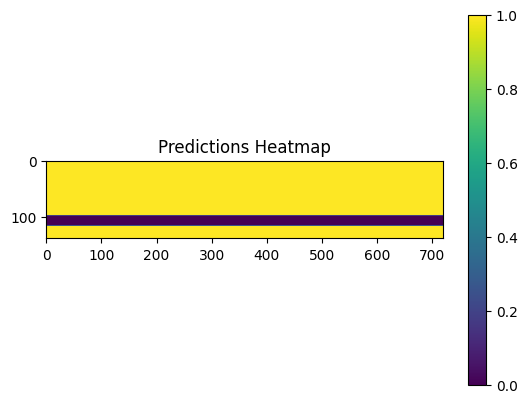

In [ ]:
plt.imshow(pickled_data)
plt.title('Predictions Heatmap')
plt.colorbar()
plt.show()